# 📰 영어 뉴스 텍스트 분석 및 시각화

이 노트북에서는 SQLite 데이터베이스(`data.db`)의 뉴스 뷰(`view_news_title_content`)를 조회하여 다음 작업을 수행합니다:
1. **데이터 조회**: `data.db`의 `view_news_title_content` 뷰에서 기사 제목과 본문 불러오기
2. **단어 빈도수 집계**: 불용어(Stopwords)를 제외한 영단어 출현 횟수 계산
3. **막대그래프 & 워드 클라우드 시각화**: 상위 단어 빈도수 시각화
4. **SQLite 테이블 저장**: 집계된 단어 빈도수를 `data.db`의 `word_count` 테이블로 저장
5. **단어 네트워크(Word Co-occurrence Network) 시각화**: 함께 자주 등장하는 단어 간의 관계 네트워크 분석

### 📦 0. 필수 라이브러리 설치
코드를 실행하기 전에 필요한 외부 라이브러리(`pandas`, `matplotlib`, `wordcloud`, `networkx`, `koreanize-matplotlib`, `deep-translator`)를 설치합니다.

In [21]:
# 필요한 라이브러리 설치
%pip install pandas matplotlib wordcloud networkx koreanize-matplotlib deep-translator

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


### 📚 라이브러리 임포트
분석 및 시각화에 필요한 모듈을 불러오고 `koreanize_matplotlib`을 통해 한글 폰트를 자동 설정합니다.

In [22]:
import sqlite3
import re
from collections import Counter
import itertools

import pandas as pd
import matplotlib.pyplot as plt
import koreanize_matplotlib  # 한글 폰트 자동 설정
from wordcloud import WordCloud
import networkx as nx

print("라이브러리 임포트 완료!")

라이브러리 임포트 완료!


## 1. SQLite 뷰(`view_news_title_content`) 데이터 불러오기

In [23]:
# SQLite data.db 연결
conn = sqlite3.connect('data.db')

# view_news_title_content 뷰에서 데이터 조회
df_news = pd.read_sql_query("SELECT * FROM view_news_title_content", conn)

print(f"총 뉴스 기사 수: {len(df_news)}개")
df_news.head()

총 뉴스 기사 수: 5개


,제목,내용
0,Saudi minister vows 'serious response' to Hout...,A Saudi minister has vowed a serious response ...
1,Iran-Backed Militants Are Tightening the Screw...,Iran-backed Houthi militants in Yemen are inte...
2,Saudi Arabia will have to respond to Houthi ai...,Saudi leaders face tough strategic dilemmas fo...
3,Saudi and Yemeni Airports Hit in New Round of ...,Airports across Saudi Arabia and Yemen have be...
4,Trump bears down on Zelensky as Russia keeps u...,Donald Trump increased diplomatic pressure on ...


## 2. 영단어 추출 및 불용어(Stopwords) 제거 후 빈도수 집계
뉴스 기사의 제목과 내용에서 텍스트를 추출하고, 빈번하지만 의미 분석에 불필요한 기능어(the, a, is, of, to 등)를 제외한 뒤 단어 빈도수를 계산합니다.

In [24]:
# 기본 영어 불용어(Stopwords) 정의
STOPWORDS = {
    'the', 'a', 'an', 'and', 'or', 'but', 'in', 'on', 'at', 'to', 'for', 'of', 'with', 
    'by', 'from', 'up', 'about', 'into', 'over', 'after', 'is', 'are', 'was', 'were', 
    'be', 'been', 'being', 'have', 'has', 'had', 'do', 'does', 'did', 'will', 'would', 
    'should', 'could', 'can', 'may', 'might', 'must', 'that', 'this', 'these', 'those', 
    'it', 'its', 'they', 'them', 'their', 'he', 'him', 'his', 'she', 'her', 'we', 'us', 
    'our', 'you', 'your', 'i', 'me', 'my', 'as', 'if', 'not', 'no', 'so', 'than', 'too', 
    'very', 's', 't', 're', 've', 'd', 'll', 'm', 'says', 'said', 'also', 'more', 'while'
}

all_words = []
article_words_list = []  # 기사별 단어 리스트 (네트워크 시각화에 활용)

for _, row in df_news.iterrows():
    # 제목과 내용을 소문자로 변환하여 결합
    text = f"{row['제목']} {row['내용']}".lower()
    
    # 2글자 이상의 알파벳 단어 추출
    words = re.findall(r"\b[a-z]{2,}\b", text)
    
    # 불용어 제외
    clean_words = [w for w in words if w not in STOPWORDS]
    
    all_words.extend(clean_words)
    article_words_list.append(clean_words)

# 단어별 빈도수 집계
word_counts = Counter(all_words)

# 빈도수 데이터프레임 생성
df_words = pd.DataFrame(word_counts.most_common(), columns=['word', 'count'])

print(f"총 단어 수: {len(all_words)}개, 고유 단어 수: {len(df_words)}개")
df_words.head(15)

총 단어 수: 229개, 고유 단어 수: 151개


,word,count
0,saudi,10
1,arabia,6
2,houthi,5
3,strikes,5
4,against,5
5,attacks,4
6,airports,4
7,military,4
8,infrastructure,4
9,yemen,3


## 3. 단어 빈도수 막대그래프(Bar Chart) 시각화
가장 많이 출현한 상위 20개 단어의 빈도수를 가로 막대그래프로 시각화합니다.

💾 막대그래프가 'word_frequency_barchart.png'로 저장되었습니다.


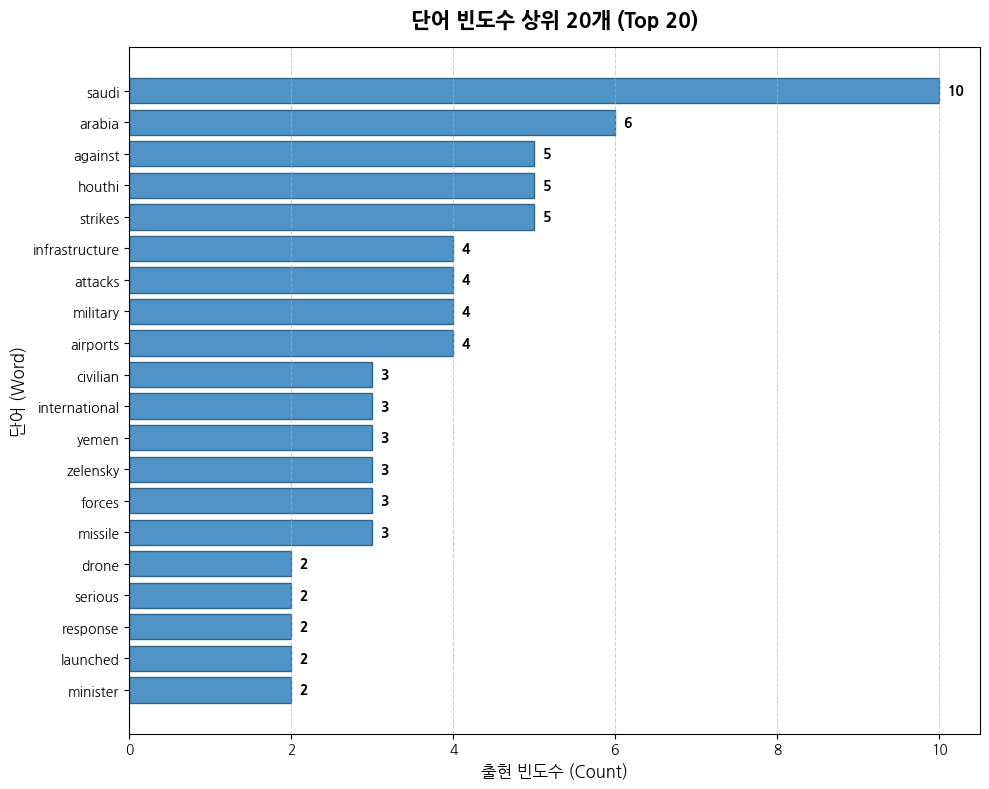

In [25]:
# 상위 20개 단어 추출
top20 = df_words.head(20).sort_values(by="count", ascending=True)

plt.figure(figsize=(10, 8))
bars = plt.barh(top20["word"], top20["count"], color="#3182bd", edgecolor="#1c5380", alpha=0.85)

# 막대 끝에 빈도수 숫자 표시
for bar in bars:
    width = bar.get_width()
    plt.text(width + 0.1, bar.get_y() + bar.get_height() / 2, 
             f"{int(width)}", 
             va="center", ha="left", fontsize=10, fontweight="bold")

plt.title("단어 빈도수 상위 20개 (Top 20)", fontsize=15, fontweight="bold", pad=15)
plt.xlabel("출현 빈도수 (Count)", fontsize=12)
plt.ylabel("단어 (Word)", fontsize=12)
plt.grid(axis="x", linestyle="--", alpha=0.6)
plt.tight_layout()

# 이미지 파일로 저장 (plt.show() 전에 호출해야 정상 저장됨)
plt.savefig("word_frequency_barchart.png", dpi=300, bbox_inches="tight")
print("💾 막대그래프가 'word_frequency_barchart.png'로 저장되었습니다.")
plt.show()

## 4. 워드 클라우드(Word Cloud) 시각화
단어의 출현 빈도에 따라 글자의 크기를 다르게 표시하는 워드 클라우드를 생성합니다.

💾 워드 클라우드가 'wordcloud.png'로 저장되었습니다.


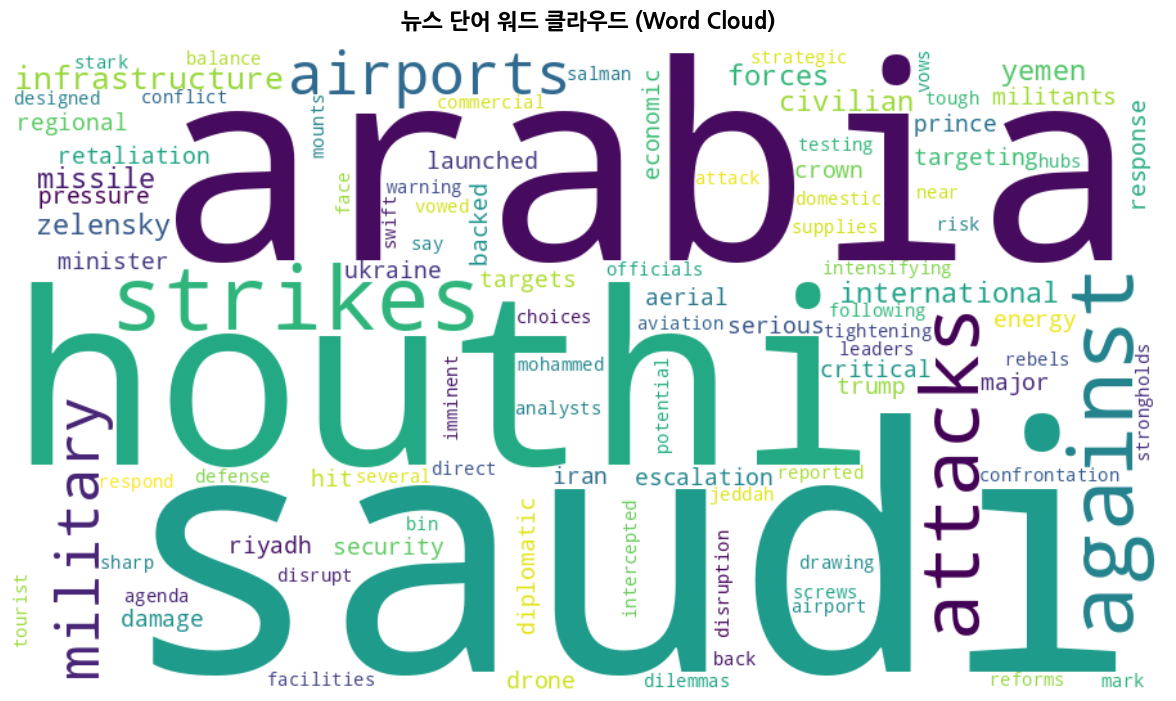

In [26]:
# 워드 클라우드 생성
wc = WordCloud(
    width=900, 
    height=500, 
    background_color="white",
    colormap="viridis",
    max_words=100,
    random_state=42
).generate_from_frequencies(word_counts)

plt.figure(figsize=(12, 7))
plt.imshow(wc, interpolation="bilinear")
plt.axis("off")
plt.title("뉴스 단어 워드 클라우드 (Word Cloud)", fontsize=16, fontweight="bold", pad=15)
plt.tight_layout()

# 이미지 파일로 저장
plt.savefig("wordcloud.png", dpi=300, bbox_inches="tight")
print("💾 워드 클라우드가 'wordcloud.png'로 저장되었습니다.")
plt.show()

## 5. `deep-translator`로 API 키 없이 자동 번역 및 `view_word_count` 뷰 생성

복잡한 웹 통신 코드 없이, 누구나 쉽게 쓸 수 있는 **`deep-translator`** 라이브러리를 사용하여 영단어를 한국어로 자동 번역합니다.
- 👶 **고등학생 친화적 코드**: 웹/네트워크 지식 없이 `translator.translate(단어)` 단 한 줄로 번역
- 🔑 **API 키 전혀 불필요**: 별도 가입이나 키 발급 없이 즉시 실행 가능
- 🔄 **완전 자동화**: 뉴스 기사가 바뀌어도 결과를 미리 적어둘 필요 없이 자동 번역

In [27]:
from deep_translator import MyMemoryTranslator

# 1. API 키가 필요 없는 번역기 생성 (영어 -> 한국어)
translator = MyMemoryTranslator(source='english', target='korean')

# 2. 번역 함수 정의 (오류 발생 시 에러 없이 영단어 유지)
def translate_word(word):
    try:
        return translator.translate(word)
    except Exception:
        return word

print("⏳ deep-translator로 주요 영단어를 자동 번역하는 중...")

# 3. 상위 30개 주요 단어 자동 번역 적용 (수업 진행 속도 고려)
top_30_words = set(df_words.head(30)['word'])
df_words['한국어'] = df_words['word'].apply(lambda w: translate_word(w) if w in top_30_words else '-')
df_words = df_words[['word', 'count', '한국어']]

# 4. data.db에 word_count 테이블로 저장
df_words.to_sql('word_count', conn, if_exists='replace', index=False)
conn.commit()

# 5. SQLite에 view_word_count 뷰 생성
cursor = conn.cursor()
cursor.execute("DROP VIEW IF EXISTS view_word_count")
cursor.execute("""
CREATE VIEW view_word_count AS
SELECT 
    word AS [영단어],
    count AS [빈도수],
    한국어 AS [한국어뜻]
FROM word_count
""")
conn.commit()

# 6. 생성된 뷰에서 상위 15개 조회
df_view = pd.read_sql_query("SELECT * FROM view_word_count LIMIT 15", conn)
print("✅ deep-translator 자동 번역이 적용된 'view_word_count' 뷰 생성 완료!")
df_view

⏳ deep-translator로 주요 영단어를 자동 번역하는 중...
✅ deep-translator 자동 번역이 적용된 'view_word_count' 뷰 생성 완료!


,영단어,빈도수,한국어뜻
0,saudi,10,사우디식
1,arabia,6,아라비아
2,houthi,5,후티
3,strikes,5,동맹파업
4,against,5,에 대하여
5,attacks,4,공격
6,airports,4,공항
7,military,4,군대
8,infrastructure,4,인프라스트럭처
9,yemen,3,예멘


## 6. 가까운 단어끼리만 묶는 단어 네트워크(Word Co-occurrence Network) 시각화

모든 단어를 무조건 다 연결하면 거미줄처럼 너무 얽혀서 내용을 파악하기 어렵습니다.
따라서 **문장 내에서 실제로 가까이 붙어 있는 단어(앞뒤 4단어 이내)**들만 연결하고, **2회 이상 함께 등장한 단어 쌍**만 시각화하여 주제별 단어 묶음이 한눈에 보이도록 개선합니다.
- 📏 **슬라이딩 윈도우 (Window Size = 4)**: 같은 문장 안에서 4단어 이내로 인접한 단어만 짝짓기
- 🎯 **최소 등장 횟수 필터 (Threshold >= 2)**: 우연히 1번 나온 관계는 제외하고, 자주 함께 쓰인 핵심 짝꿍 단어만 연결
- 🟢 **노드 크기**: 단어의 전체 빈도수에 비례 / **선 굵기**: 함께 붙어 나온 횟수에 비례

연결된 핵심 단어 수: 15개, 연결선(관계) 수: 20개
💾 정제된 단어 네트워크 그래프가 'word_network.png'로 저장되었습니다.


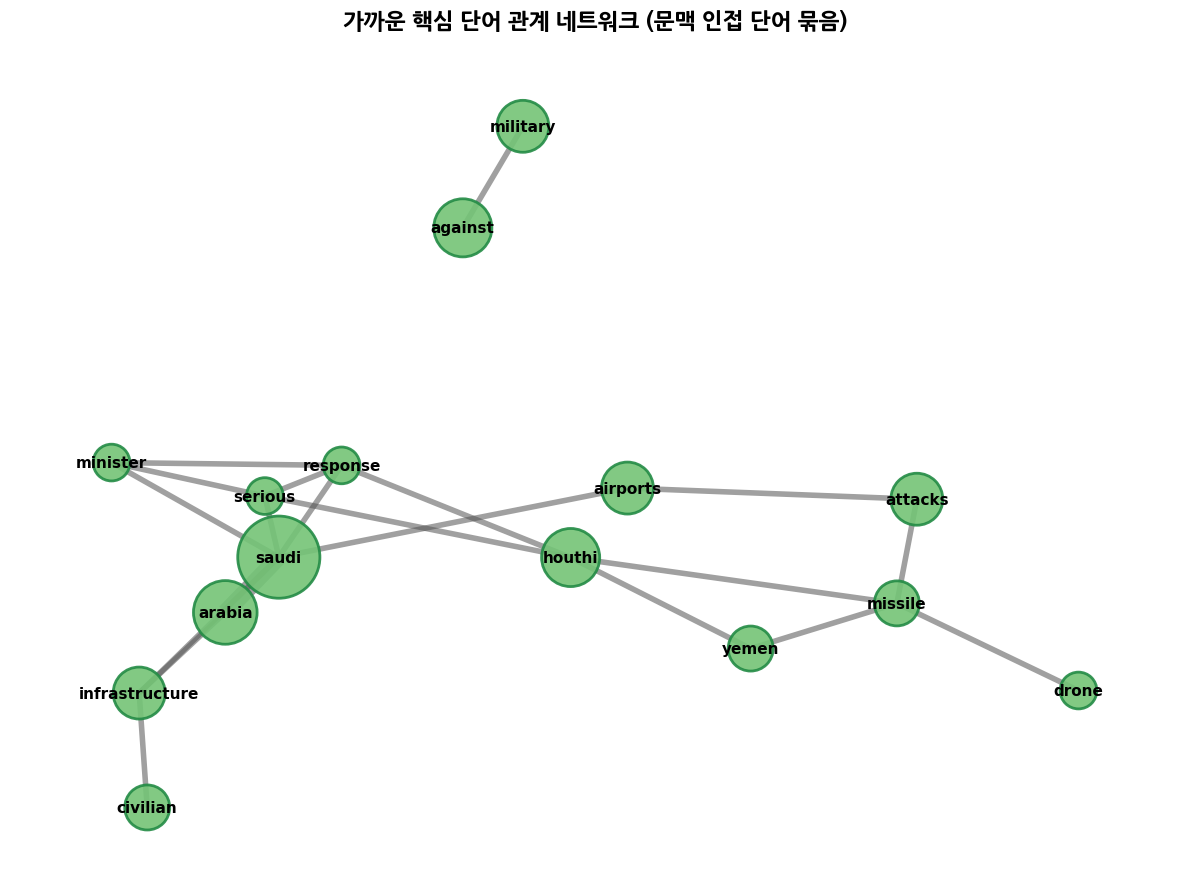

모든 분석 및 저장이 완료되었습니다!


In [28]:
# 1. 기사를 문장 단위로 분리하고 불용어 제거
sentences_words = []
for _, row in df_news.iterrows():
    full_text = f"{row['제목']}. {row['내용']}".lower()
    sentences = re.split(r"[.!?]+", full_text)
    for s in sentences:
        words = [w for w in re.findall(r"\b[a-z]{2,}\b", s) if w not in STOPWORDS]
        if words:
            sentences_words.append(words)

# 분석 대상 상위 25개 단어
TOP_N = 25
top_words = set(df_words.head(TOP_N)['word'])

# 2. 같은 문장 내에서 가까운 거리(앞뒤 4단어 이내)에 있는 단어 쌍만 카운트
WINDOW_SIZE = 4
co_occurrence = Counter()

for s in sentences_words:
    for i in range(len(s)):
        w1 = s[i]
        if w1 not in top_words:
            continue
        # 앞뒤 4단어 거리 이내의 단어만 탐색
        for j in range(i + 1, min(i + WINDOW_SIZE + 1, len(s))):
            w2 = s[j]
            if w2 in top_words and w1 != w2:
                pair = tuple(sorted([w1, w2]))
                co_occurrence[pair] += 1

# 3. 네트워크 그래프 생성 (최소 2회 이상 함께 붙어 나온 관계만 연결)
G = nx.Graph()

for (w1, w2), weight in co_occurrence.items():
    if weight >= 2:  # 2회 이상 인접한 핵심 단어 쌍만 연결
        G.add_edge(w1, w2, weight=weight)

# 연결된 노드에 빈도수 정보 추가
for node in G.nodes():
    G.nodes[node]['size'] = word_counts[node]

print(f"연결된 핵심 단어 수: {len(G.nodes())}개, 연결선(관계) 수: {len(G.edges())}개")

# 4. 깔끔한 네트워크 시각화
plt.figure(figsize=(12, 9))
pos = nx.spring_layout(G, k=0.7, seed=42)

# 노드 크기 (단어 빈도수에 비례)
node_sizes = [G.nodes[node]['size'] * 350 for node in G.nodes()]
# 엣지 굵기 (함께 나온 횟수에 비례)
edge_weights = [G[u][v]['weight'] * 2.0 for u, v in G.edges()]

# 그래프 요소 그리기
nx.draw_networkx_nodes(G, pos, node_size=node_sizes, node_color="#74c476", alpha=0.9, edgecolors="#238b45", linewidths=2)
nx.draw_networkx_edges(G, pos, width=edge_weights, alpha=0.55, edge_color="#525252")
nx.draw_networkx_labels(G, pos, font_size=11, font_family="sans-serif", font_weight="bold")

plt.title("가까운 핵심 단어 관계 네트워크 (문맥 인접 단어 묶음)", fontsize=16, fontweight="bold", pad=20)
plt.axis("off")
plt.tight_layout()

# 이미지 파일로 저장
plt.savefig("word_network.png", dpi=300, bbox_inches="tight")
print("💾 정제된 단어 네트워크 그래프가 'word_network.png'로 저장되었습니다.")
plt.show()

# SQLite DB 연결 닫기
conn.close()
print("모든 분석 및 저장이 완료되었습니다!")